In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df= pd.read_csv('state-control-renewable-energy-generation.csv')
df

,id,date,state_name,state_code,region,wind_energy,solar_energy,other_renewable_energy,total_renewable_energy
0,0,2020-05-28,All India,99,NaN,323.73,131.64,40.70,496.07
1,1,2020-05-28,Andhra Pradesh,28,Southern Region,29.95,9.23,0.00,39.18
2,2,2020-05-28,Arunachal Pradesh,12,North-Eastern Region,0.00,0.00,0.00,0.00
3,3,2020-05-28,Assam,18,North-Eastern Region,0.00,0.00,0.00,0.00
4,4,2020-05-28,Bihar,10,Eastern Region,0.00,0.00,0.59,0.59
...,...,...,...,...,...,...,...,...,...
61840,61822,2025-04-27,Jammu And Kashmir,1,Northern Region,0.00,0.00,0.00,0.00
61841,61835,2025-04-27,Punjab,3,Northern Region,0.00,3.82,3.60,7.42
61842,61836,2025-04-27,Rajasthan,8,Northern Region,3.84,40.03,1.50,45.37
61843,61842,2025-04-27,Uttar Pradesh,9,Northern Region,0.00,12.80,0.00,12.80


In [4]:
print("Shape:", df.shape)
display(df.sample(min(5, len(df))))
print(df.info())
display(df.describe(include="all").T)
print("Columns:", df.columns.tolist())
print("Data types:\n", df.dtypes)

Shape: (61845, 9)


,id,date,state_name,state_code,region,wind_energy,solar_energy,other_renewable_energy,total_renewable_energy
23237,31356,2022-12-07,Tripura,16,North-Eastern Region,0.0,0.02,0.00,0.02
6540,8875,2021-02-15,Assam,18,North-Eastern Region,0.0,0.10,0.00,0.10
60976,58387,2025-01-19,Delhi,7,Northern Region,0.0,0.00,1.22,1.22
46787,3360,2020-09-04,Uttar Pradesh,9,Northern Region,0.0,5.19,0.00,5.19
10928,14797,2021-08-16,Sikkim,11,Eastern Region,0.0,0.00,0.00,0.00


<class 'pandas.DataFrame'>
RangeIndex: 61845 entries, 0 to 61844
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      61845 non-null  int64  
 1   date                    61845 non-null  str    
 2   state_name              61845 non-null  str    
 3   state_code              61845 non-null  int64  
 4   region                  60073 non-null  str    
 5   wind_energy             61797 non-null  float64
 6   solar_energy            61815 non-null  float64
 7   other_renewable_energy  61800 non-null  float64
 8   total_renewable_energy  61845 non-null  float64
dtypes: float64(4), int64(2), str(3)
memory usage: 6.3 MB
None


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,61845.0,NaN,NaN,NaN,30922.0,17853.258036,0.0,15461.0,30922.0,46383.0,61844.0
date,61845,1776,2022-08-08,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state_name,61845,35,Jharkhand,1778,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state_code,61845.0,NaN,NaN,NaN,20.569343,17.229161,1.0,9.0,18.0,29.0,99.0
region,60073,5,Northern Region,17447,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wind_energy,61797.0,NaN,NaN,NaN,9.036228,33.215295,0.0,0.0,0.0,0.61,486.83
solar_energy,61815.0,NaN,NaN,NaN,9.319911,28.678012,0.0,0.0,0.1,7.5,296.96
other_renewable_energy,61800.0,NaN,NaN,NaN,1.74055,5.875876,-5.93,0.0,0.0,0.61,114.82
total_renewable_energy,61845.0,NaN,NaN,NaN,20.083293,62.621622,-0.01,0.0,0.88,13.5,727.5


Columns: ['id', 'date', 'state_name', 'state_code', 'region', 'wind_energy', 'solar_energy', 'other_renewable_energy', 'total_renewable_energy']
Data types:
 id                          int64
date                          str
state_name                    str
state_code                  int64
region                        str
wind_energy               float64
solar_energy              float64
other_renewable_energy    float64
total_renewable_energy    float64
dtype: object


In [5]:
df.isnull().sum()

id                           0
date                         0
state_name                   0
state_code                   0
region                    1772
wind_energy                 48
solar_energy                30
other_renewable_energy      45
total_renewable_energy       0
dtype: int64

In [6]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2),
    "Unique_Values": df.nunique()
})

display(missing.sort_values("Missing_Count", ascending=False))

,Missing_Count,Missing_Percentage,Unique_Values
region,1772,2.87,5
wind_energy,48,0.08,5842
other_renewable_energy,45,0.07,2798
solar_energy,30,0.05,4986
id,0,0.00,61845
state_code,0,0.00,35
state_name,0,0.00,35
date,0,0.00,1776
total_renewable_energy,0,0.00,8309


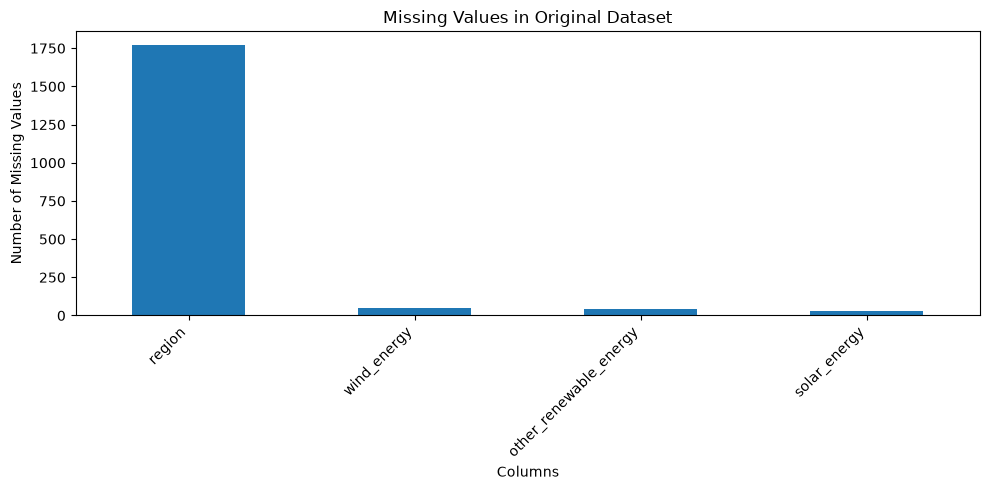

In [7]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    missing.plot(kind="bar", figsize=(10, 5))
    plt.title("Missing Values in Original Dataset")
    plt.xlabel("Columns")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

In [8]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['id', 'date', 'state_name', 'state_code', 'region', 'wind_energy', 'solar_energy', 'other_renewable_energy', 'total_renewable_energy']


In [9]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicates after:", df.duplicated().sum())
print("Shape after removing duplicates:", df.shape)

Duplicates before: 0
Duplicates after: 0
Shape after removing duplicates: (61845, 9)


In [10]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

numeric_cols = [
    "id",
    "state_code",
    "wind_energy",
    "solar_energy",
    "other_renewable_energy",
    "total_renewable_energy"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in ["state_name", "region"]:
    df[col] = df[col].astype("string").str.strip()

display(df.dtypes)


id                                 int64
date                      datetime64[us]
state_name                        string
state_code                         int64
region                            string
wind_energy                      float64
solar_energy                     float64
other_renewable_energy           float64
total_renewable_energy           float64
dtype: object

In [11]:
print("Missing values before:\n", df.isnull().sum())

# Remove records missing essential identifiers
df = df.dropna(
    subset=["date", "state_name", "state_code"]
).copy()

energy_cols = [
    "wind_energy",
    "solar_energy",
    "other_renewable_energy"
]

# Fill missing energy components with state-wise medians
for col in energy_cols:
    df[col] = df.groupby("state_name")[col].transform(
        lambda x: x.fillna(x.median())
    )
    df[col] = df[col].fillna(df[col].median())

# Reconstruct missing totals only when all components are available
component_sum = df[energy_cols].sum(axis=1, min_count=3)

df["total_renewable_energy"] = (
    df["total_renewable_energy"].fillna(component_sum)
)

df["region"] = df["region"].fillna("Unknown")

print("Missing values after:\n", df.isnull().sum())

Missing values before:
 id                           0
date                         0
state_name                   0
state_code                   0
region                    1772
wind_energy                 48
solar_energy                30
other_renewable_energy      45
total_renewable_energy       0
dtype: int64
Missing values after:
 id                        0
date                      0
state_name                0
state_code                0
region                    0
wind_energy               0
solar_energy              0
other_renewable_energy    0
total_renewable_energy    0
dtype: int64


In [12]:
for col in energy_cols + ["total_renewable_energy"]:
    print(f"{col}:")
    print("Negative values:", (df[col] < 0).sum())
    print("Zero values:", (df[col] == 0).sum())
    print("Missing values:", df[col].isnull().sum())

wind_energy:
Negative values: 0
Zero values: 44091
Missing values: 0
solar_energy:
Negative values: 0
Zero values: 27913
Missing values: 0
other_renewable_energy:
Negative values: 3
Zero values: 42048
Missing values: 0
total_renewable_energy:
Negative values: 1
Zero values: 22354
Missing values: 0


In [13]:
duplicate_keys = df[
    df.duplicated(subset=["date", "state_name"], keep=False)
]

print("Duplicate state-date records:", len(duplicate_keys))
display(duplicate_keys.head(10))

Duplicate state-date records: 4


,id,date,state_name,state_code,region,wind_energy,solar_energy,other_renewable_energy,total_renewable_energy
508,689,2020-06-18,Jharkhand,20,Eastern Region,0.0,0.0,0.25,0.25
509,690,2020-06-18,Jharkhand,20,Eastern Region,0.0,0.0,0.00,0.00
5970,8102,2021-01-22,Jharkhand,20,Eastern Region,0.0,0.0,0.00,0.00
5971,8103,2021-01-22,Jharkhand,20,Eastern Region,0.0,0.0,1.28,1.28


In [14]:
df=df.drop([509,5971])

In [15]:
df.shape

(61843, 9)

In [16]:
mapping_check = df.groupby("state_name")["state_code"].nunique()
print("Max unique codes per state:", mapping_check.max())

inconsistent_states = mapping_check[mapping_check > 1]
if not inconsistent_states.empty:
    print("States with multiple codes:", inconsistent_states)
else:
    print("All state names have a 1-to-1 mapping with state codes.")

Max unique codes per state: 1
All state names have a 1-to-1 mapping with state codes.


In [17]:
outlier_results = []

for col in energy_cols + ["total_renewable_energy"]:
  q1 = df[col].quantile(0.25)
  q3 = df[col].quantile(0.75)
  iqr = q3 - q1

  lower = q1 - 1.5 * iqr
  upper = q3 + 1.5 * iqr

  is_outlier = (df[col] < lower) | (df[col] > upper)

  outlier_results.append({
      "Column": col,
      "Q1": q1,
      "Q3": q3,
      "IQR": iqr,
      "Lower_Bound": lower,
      "Upper_Bound": upper,
      "Outlier_Count": is_outlier.sum(),
  })

display(pd.DataFrame(outlier_results))

,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count
0,wind_energy,0.0,0.605,0.605,-0.9075,1.5125,14233
1,solar_energy,0.0,7.500,7.500,-11.2500,18.7500,7947
2,other_renewable_energy,0.0,0.610,0.610,-0.9150,1.5250,9899
3,total_renewable_energy,0.0,13.500,13.500,-20.2500,33.7500,8426


In [18]:
df

,id,date,state_name,state_code,region,wind_energy,solar_energy,other_renewable_energy,total_renewable_energy
0,0,2020-05-28,All India,99,Unknown,323.73,131.64,40.70,496.07
1,1,2020-05-28,Andhra Pradesh,28,Southern Region,29.95,9.23,0.00,39.18
2,2,2020-05-28,Arunachal Pradesh,12,North-Eastern Region,0.00,0.00,0.00,0.00
3,3,2020-05-28,Assam,18,North-Eastern Region,0.00,0.00,0.00,0.00
4,4,2020-05-28,Bihar,10,Eastern Region,0.00,0.00,0.59,0.59
...,...,...,...,...,...,...,...,...,...
61840,61822,2025-04-27,Jammu And Kashmir,1,Northern Region,0.00,0.00,0.00,0.00
61841,61835,2025-04-27,Punjab,3,Northern Region,0.00,3.82,3.60,7.42
61842,61836,2025-04-27,Rajasthan,8,Northern Region,3.84,40.03,1.50,45.37
61843,61842,2025-04-27,Uttar Pradesh,9,Northern Region,0.00,12.80,0.00,12.80


<Axes: xlabel='wind_energy'>

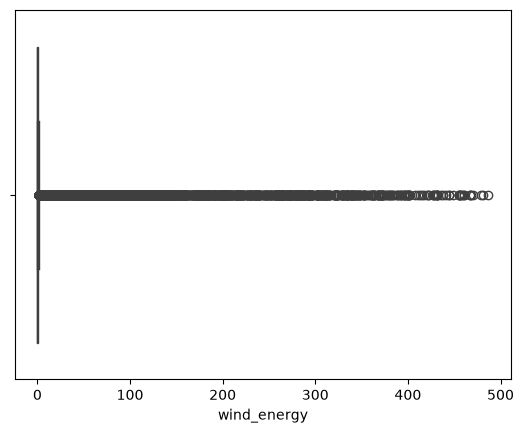

In [18]:
sns.boxplot(data=df,x=df['wind_energy'])

In [19]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
display(df.head())

,id,date,state_name,state_code,region,wind_energy,solar_energy,other_renewable_energy,total_renewable_energy,year,month
0,0,2020-05-28,All India,99,Unknown,323.73,131.64,40.70,496.07,2020,5
1,1,2020-05-28,Andhra Pradesh,28,Southern Region,29.95,9.23,0.00,39.18,2020,5
2,2,2020-05-28,Arunachal Pradesh,12,North-Eastern Region,0.00,0.00,0.00,0.00,2020,5
3,3,2020-05-28,Assam,18,North-Eastern Region,0.00,0.00,0.00,0.00,2020,5
4,4,2020-05-28,Bihar,10,Eastern Region,0.00,0.00,0.59,0.59,2020,5


In [20]:
total = df["total_renewable_energy"].where(
    df["total_renewable_energy"] > 0
)

df["wind_share"] = df["wind_energy"] / total
df["solar_share"] = df["solar_energy"] / total
df["other_renewable_share"] = df["other_renewable_energy"] / total

display(
    df[[
        "state_name",
        "wind_share",
        "solar_share",
        "other_renewable_share"
    ]].head()
)

,state_name,wind_share,solar_share,other_renewable_share
0,All India,0.652589,0.265366,0.082045
1,Andhra Pradesh,0.764421,0.235579,0.000000
2,Arunachal Pradesh,NaN,NaN,NaN
3,Assam,NaN,NaN,NaN
4,Bihar,0.000000,0.000000,1.000000


In [21]:
df["calculated_total"] = df[energy_cols].sum(
    axis=1, min_count=3
)

df["total_difference"] = (
    df["total_renewable_energy"] - df["calculated_total"]
)

display(
    df.loc[
        df["total_difference"].abs() > 0.02,
        ["state_name", "date"] + energy_cols
        + ["calculated_total", "total_difference"]
    ].head(20)
)

,state_name,date,wind_energy,solar_energy,other_renewable_energy,calculated_total,total_difference
24593,All India,2023-01-30,99.46,144.63,24.84,268.93,-18.38
24615,Telangana,2023-01-30,1.05,17.33,0.00,18.38,-18.38
28967,Bihar,2023-07-17,0.00,0.56,0.00,0.56,0.52
28981,Odisha,2023-07-17,0.00,1.08,0.00,1.08,-0.52
33309,Bihar,2023-12-31,0.00,0.46,0.35,0.81,-0.35
33323,Odisha,2023-12-31,0.00,1.86,1.08,2.94,-1.08
33330,West Bengal,2023-12-31,0.00,0.00,2.60,2.60,-2.60
35518,Assam,2024-03-25,0.00,0.55,0.00,0.55,-0.55
35519,Bihar,2024-03-25,0.00,0.00,0.35,0.35,-0.35
35533,Odisha,2024-03-25,0.00,0.00,1.08,1.08,-1.08


In [22]:
finaldf=df

In [23]:
monthly_df = (
    finaldf
    .set_index("date")
    .groupby(["state_name","state_code"])[
        [
            "wind_energy",
            "solar_energy",
            "other_renewable_energy",
            "total_renewable_energy"
        ]
    ]
    .resample("MS")
    .sum(min_count=1)
    .reset_index()
)

display(monthly_df.head())
print("Monthly dataset shape:", monthly_df.shape)

,state_name,state_code,date,wind_energy,solar_energy,other_renewable_energy,total_renewable_energy
0,All India,99,2020-05-01,810.27,378.02,88.29,1276.58
1,All India,99,2020-06-01,6191.30,2920.54,857.31,9969.15
2,All India,99,2020-07-01,6012.11,3288.43,986.33,10286.87
3,All India,99,2020-08-01,8302.71,2902.29,1108.04,12313.04
4,All India,99,2020-09-01,4074.09,3103.13,960.84,8138.06


Monthly dataset shape: (2089, 7)


In [24]:
yearly_df = (
    finaldf
    .groupby(["state_name", "year"], as_index=False)[
        [
            "wind_energy",
            "solar_energy",
            "other_renewable_energy",
            "total_renewable_energy"
        ]
    ]
    .sum(min_count=1)
)

display(yearly_df.head())

,state_name,year,wind_energy,solar_energy,other_renewable_energy,total_renewable_energy
0,All India,2020,34337.23,22790.08,6744.35,63871.66
1,All India,2021,53421.24,45090.34,10212.82,108724.40
2,All India,2022,56718.23,54346.35,14455.38,125519.96
3,All India,2023,62113.13,63914.54,8993.28,135002.57
4,All India,2024,58863.96,71767.09,9969.38,140600.43


In [31]:
finaldf.to_csv("cleaned_renewable_energy.csv", index=False)
monthly_df.to_csv("monthly_renewable_energy.csv", index=False)
yearly_df.to_csv("yearly_renewable_energy.csv", index=False)


print("All processed datasets saved successfully.")

All processed datasets saved successfully.


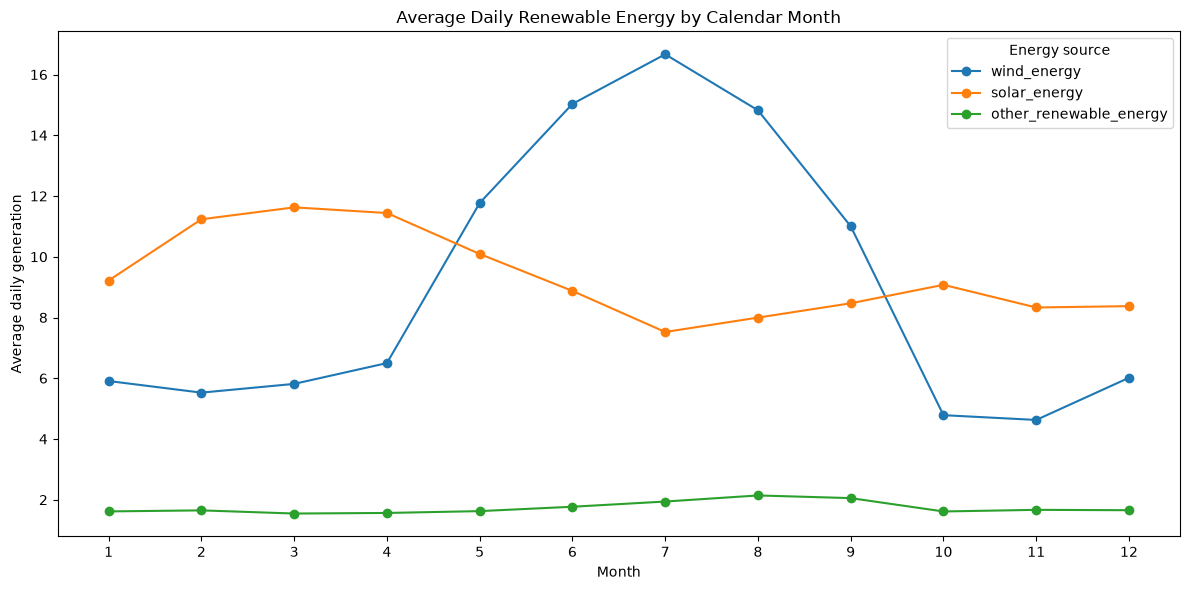

In [26]:
monthly_seasonality = (
    finaldf.assign(month=finaldf["date"].dt.month)
    .groupby("month")[energy_cols]
    .mean()
)

monthly_seasonality.plot(
    marker="o",
    figsize=(12, 6)
)

plt.title("Average Daily Renewable Energy by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average daily generation")
plt.xticks(range(1, 13))
plt.legend(title="Energy source")
plt.tight_layout()
plt.show()

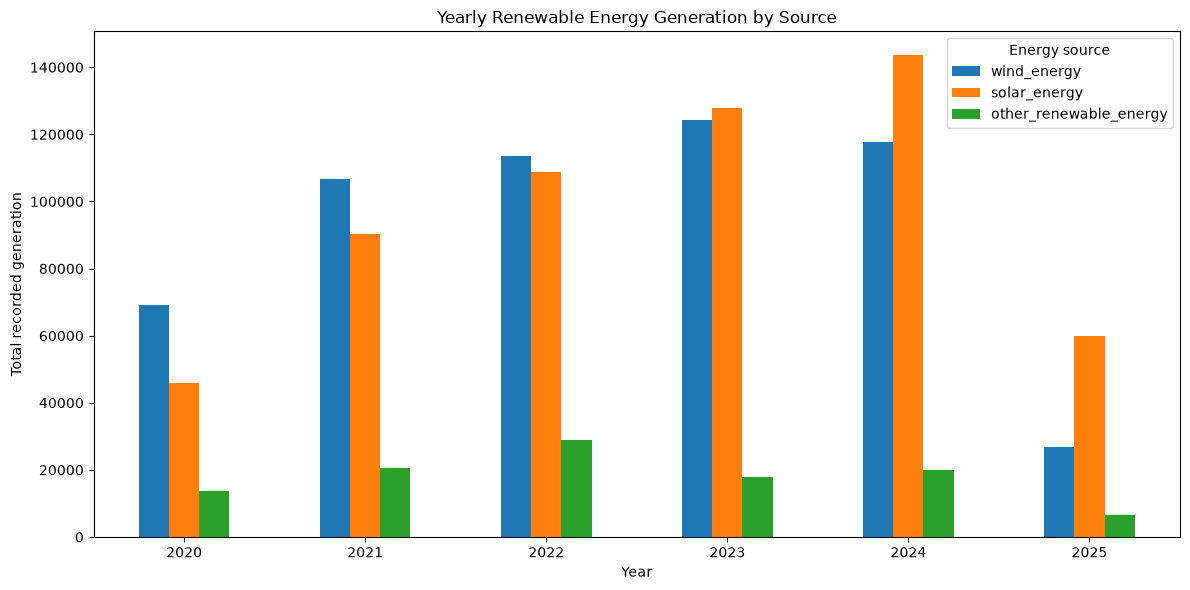

In [27]:
yearly_sources = (
    finaldf.groupby(finaldf["date"].dt.year)[
        ["wind_energy", "solar_energy", "other_renewable_energy"]
    ].sum(min_count=1)
)

yearly_sources.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Yearly Renewable Energy Generation by Source")
plt.xlabel("Year")
plt.ylabel("Total recorded generation")
plt.xticks(rotation=0)
plt.legend(title="Energy source")
plt.tight_layout()
plt.show()

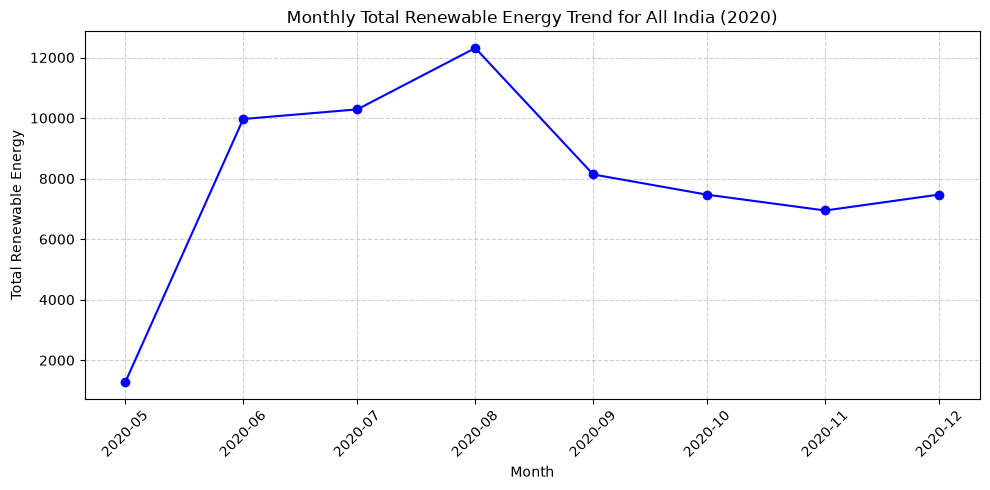

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for a single state and a full year of data (e.g., the first complete year)
sample_state = monthly_df["state_name"].unique()[0]
state_data = monthly_df[monthly_df["state_name"] == sample_state]

# Filter for a specific year that has complete data (e.g., the first year in the dataset)
target_year = state_data["date"].dt.year.min()
year_data = state_data[state_data["date"].dt.year == target_year]

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(year_data["date"], year_data["total_renewable_energy"], marker="o", linestyle="-", color="b")

plt.title(f"Monthly Total Renewable Energy Trend for {sample_state} ({target_year})")
plt.xlabel("Month")
plt.ylabel("Total Renewable Energy")
plt.grid(True, linestyle="--", alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

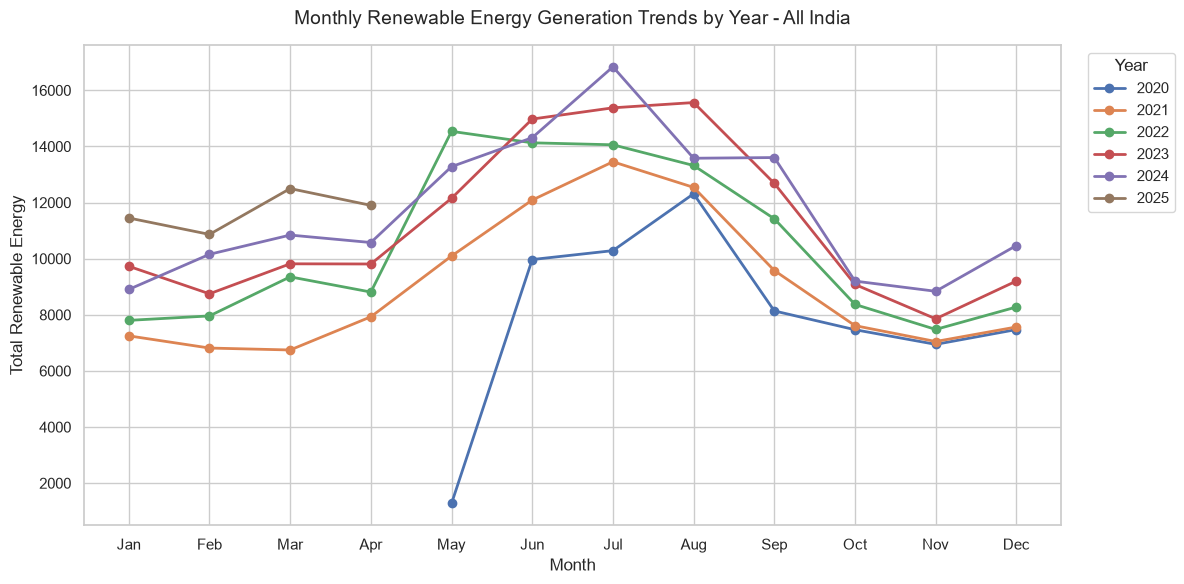

In [29]:

# Set visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Extract year and month number (1-12) for overlaying different years
monthly_df["year"] = monthly_df["date"].dt.year
monthly_df["month_number"] = monthly_df["date"].dt.month

# Choose a sample state
sample_state = monthly_df["state_name"].unique()[0]
state_data = monthly_df[monthly_df["state_name"] == sample_state]

# Plot each year as a separate line
for year, group in state_data.groupby("year"):
    plt.plot(
        group["month_number"], 
        group["total_renewable_energy"], 
        marker="o", 
        linewidth=2, 
        label=str(year)
    )

# Formatting the plot
plt.title(f"Monthly Renewable Energy Generation Trends by Year - {sample_state}", fontsize=14, pad=15)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Renewable Energy", fontsize=12)

# Set x-ticks to display month names instead of numbers
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
plt.xticks(ticks=range(1, 13), labels=month_labels)

# Place legend cleanly outside or in the best corner
plt.legend(title="Year", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.show()